In [23]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import json
import urllib.parse
import urllib.request

In [40]:
# set up
def find_root(marker: str = "pyproject.toml") -> Path:
    path = Path.cwd().resolve()
    while not (path / marker).exists():
        if path.parent == path:
            raise FileNotFoundError(f"No {marker} found above {Path.cwd()}")
        path = path.parent
    return path

ROOT = find_root()
RAW = ROOT / "data" / "raw" / "vegetation" / "ODK Data Exports"
ENT = ROOT / "data" / "raw" / "vegetation" / "Entity lists"
OUT = ROOT / "data" / "output" / "vegetation"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


# Read data

In [5]:
EXPECTED = {
    "herbaceous_veg_survey.csv": ["KEY", "ReviewState", "plot_selection-selected_plot_uuid",
                                  "survey_begin-start_time", "survey_end-end_time"],
    "herbaceous_veg_survey-quadrat_repeat.csv": ["KEY", "PARENT_KEY", "quadrat_number", "herbs_present",
                                                 "location_quadrat-Latitude", "location_quadrat-Longitude"],
    "herbaceous_veg_survey-additional_species_repeat.csv": ["KEY", "PARENT_KEY", "species_entry_mode",
                                                            "target_extra_name", "select_reuse_unknown",
                                                            "select_reuse_missing"],
    "register_vegetation_plots.csv": ["KEY", "plot_selection-selected_plot_uuid",
                                      "plot_selection-is_plot_viable"],
}

# first quality check: are all columns in the CSV as expected
def read(folder, name, expected=()):
    df = pd.read_csv(folder / name)
    missing = [c for c in expected if c not in df.columns]
    if missing:
        raise ValueError(f"{name}: missing columns {missing}")
    return df


survey_raw = read(RAW, "herbaceous_veg_survey.csv", EXPECTED["herbaceous_veg_survey.csv"])
quadrat_raw = read(RAW, "herbaceous_veg_survey-quadrat_repeat.csv",
                   EXPECTED["herbaceous_veg_survey-quadrat_repeat.csv"])
addsp_raw = read(RAW, "herbaceous_veg_survey-additional_species_repeat.csv",
                 EXPECTED["herbaceous_veg_survey-additional_species_repeat.csv"])
reg_raw = read(RAW, "register_vegetation_plots.csv", EXPECTED["register_vegetation_plots.csv"])

# these tables won't be updated frequently, so we're not checking the columns
species = read(ENT, "species.csv")
species_extra = read(ENT, "species_extra.csv")
species_ids = read(ENT, "species_extra_ids.csv")
vegplots = read(ENT, "vegplots.csv")
centroids = read(ENT, "centroids.csv")

# print shapes of all exported tables
for name, df in [("surveys", survey_raw), ("quadrats", quadrat_raw), ("additional species", addsp_raw),
                 ("plot registrations", reg_raw)]:
    print(f"{name:20s} {df.shape}")

surveys              (32, 52)
quadrats             (640, 21)
additional species   (1296, 30)
plot registrations   (31, 82)


### Plots: registration, prescribed centroid and transect geometry

In [ ]:
def xy_m(lat, lon, lat0, lon0):
    """Local equirectangular projection in metres around (lat0, lon0). Accurate to < 0.1 % at plot scale."""
    x = (np.asarray(lon) - lon0) * 111_320 * np.cos(np.radians(lat0))
    y = (np.asarray(lat) - lat0) * 110_574
    return x, y


def dist_m(lat1, lon1, lat2, lon2):
    x, y = xy_m(lat1, lon1, lat2, lon2)
    return np.hypot(x, y)


P = "plot_metadata-collect_points-"

# create new data frame for plots
plots = pd.DataFrame({
    "plot_uuid": reg_raw["plot_selection-selected_plot_uuid"],
    "plot_name": reg_raw["plot_selection-plot_name"],
    "plot_status": reg_raw["plot_selection-sample_status"],
    "is_viable": reg_raw["plot_selection-is_plot_viable"],
    "not_viable_reason": reg_raw["plot_selection-plot_establishment_notes"],
    "ecosystem_type": reg_raw["plot_metadata-ecosystem_type_name"],
    "registered_at": pd.to_datetime(reg_raw["survey_begin-start_time"], utc=True),
})

# GPS columns per transect point, e.g. midpoint_lat, midpoint_lon, midpoint_acc.
COORD_SUFFIX = {"Latitude": "lat", "Longitude": "lon", "Accuracy": "acc"}
for point in ["endpoint_a", "midpoint", "endpoint_b"]:
    for coord, suffix in COORD_SUFFIX.items():
        source_col = f"{P}{point}-location_{point}-{coord}"
        plots[f"{point}_{suffix}"] = reg_raw[source_col]

# vegplots is the entity the survey form selects from. Its __id is what surveys reference.
plots = plots.merge(vegplots[["__id", "plot_uuid"]].rename(columns={"__id": "vegplot_id"}), on="plot_uuid",
                    how="left")

# geometry is a space-separated string that starts with "lat lon".
coords = centroids["geometry"].str.split(expand=True)
cent = centroids[["__id", "stratum_label"]].copy()
cent["centroid_lat"] = coords[0].astype(float)
cent["centroid_lon"] = coords[1].astype(float)

plots = plots.merge(cent, left_on="plot_uuid", right_on="__id", how="left").drop(columns="__id")

plots["midpoint_shift_m"] = dist_m(plots["midpoint_lat"], plots["midpoint_lon"],
                                   plots["centroid_lat"], plots["centroid_lon"])
plots["a_to_mid_m"] = dist_m(plots["endpoint_a_lat"], plots["endpoint_a_lon"], plots["midpoint_lat"], plots["midpoint_lon"])
plots["b_to_mid_m"] = dist_m(plots["endpoint_b_lat"], plots["endpoint_b_lon"], plots["midpoint_lat"], plots["midpoint_lon"])
plots["transect_length_m"] = dist_m(plots["endpoint_a_lat"], plots["endpoint_a_lon"],
                                    plots["endpoint_b_lat"], plots["endpoint_b_lon"])
bx, by = xy_m(plots["endpoint_b_lat"], plots["endpoint_b_lon"], plots["endpoint_a_lat"], plots["endpoint_a_lon"])
plots["bearing_deg"] = np.degrees(np.arctan2(bx, by)) % 180  # 0 = north-south, 90 = east-west
plots["bearing_deviation_deg"] = np.minimum(plots["bearing_deg"], 180 - plots["bearing_deg"])

In [14]:
plots.head()

,plot_uuid,plot_name,plot_status,is_viable,not_viable_reason,ecosystem_type,registered_at,endpoint_a_lat,endpoint_a_lon,endpoint_a_acc,...,vegplot_id,stratum_label,centroid_lat,centroid_lon,midpoint_shift_m,a_to_mid_m,b_to_mid_m,transect_length_m,bearing_deg,bearing_deviation_deg
0,40b5b142-18e5-45da-afa8-4837f520f2cf,SavMon_LW_Plot_16,primary,yes,NaN,Scrub,2026-05-26 14:35:41.501000+00:00,0.219611,37.480986,3.70,...,b1e1fc7f-afbd-404c-bd6c-55b172d722df,savanna,0.219546,37.481244,3.513521,33.134142,25.267031,58.315700,100.311194,79.688806
1,d5645424-6bd7-4ccb-8c86-821984f00e5c,SavMon_LW_Plot_11,primary,yes,NaN,Scrub,2026-05-26 13:14:00.606000+00:00,0.222389,37.466365,4.65,...,e3135c68-679c-4b44-a083-5dc111683665,savanna,0.222328,37.466554,11.516563,27.237764,20.938171,42.495805,107.786717,72.213283
2,5fc30b9c-edc3-410d-8eb9-e9eceb8526dc,SavMon_LW_Plot_29,primary,yes,NaN,Scrub,2026-05-26 09:06:08.301000+00:00,0.226720,37.460463,4.80,...,153ee0a8-8628-4891-8c66-a5d8286552f8,savanna,0.226638,37.460777,8.282993,30.495211,32.432648,61.856345,104.853055,75.146945
3,da09c7a5-a9ba-49c8-9e74-7d262e6b7eb4,SavMon_LW_Plot_21,primary,yes,NaN,Scrub,2026-05-26 07:19:08.278000+00:00,0.225578,37.456683,3.50,...,8070570d-64ca-405a-802d-4d721fdc2fe9,savanna,0.225559,37.456964,13.794754,18.437234,27.555877,44.843863,97.708725,82.291275
4,477053f7-b110-411b-abe4-5b6aadf57ab0,SavMon_LW_Plot_18,primary,yes,NaN,Scrub,2026-05-25 14:31:23.295000+00:00,0.222631,37.438949,3.30,...,a5b642c6-e8ba-4186-a1d3-5ff99852e8b0,savanna,0.222514,37.439133,2.583077,25.017481,20.757796,45.701757,113.498718,66.501282


#### Plot geometry on a map

Each panel is one plot in local metres, centred on its prescribed centroid (grey +). The grey vertical bar is the
transect the SOP asks for: 50 m running north-south through the centroid. The dashed circle is the 25 m the midpoint
may move. The blue line is what the team recorded: endpoint A, midpoint, endpoint B. The dotted line is the midpoint
shift. The first figure is the plot with the largest shift, labelled, as a guide for reading the grid.

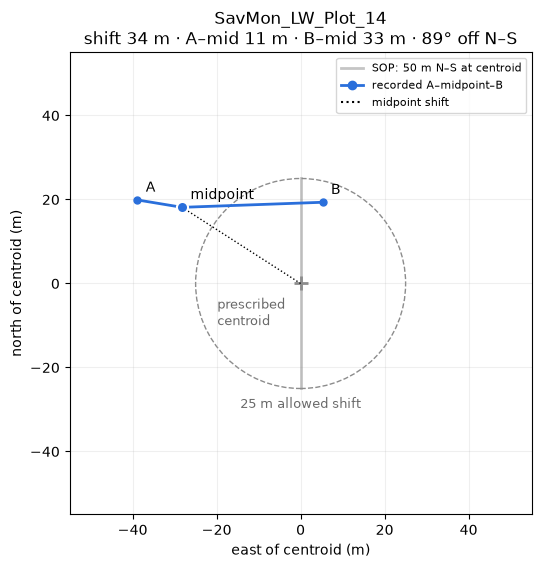

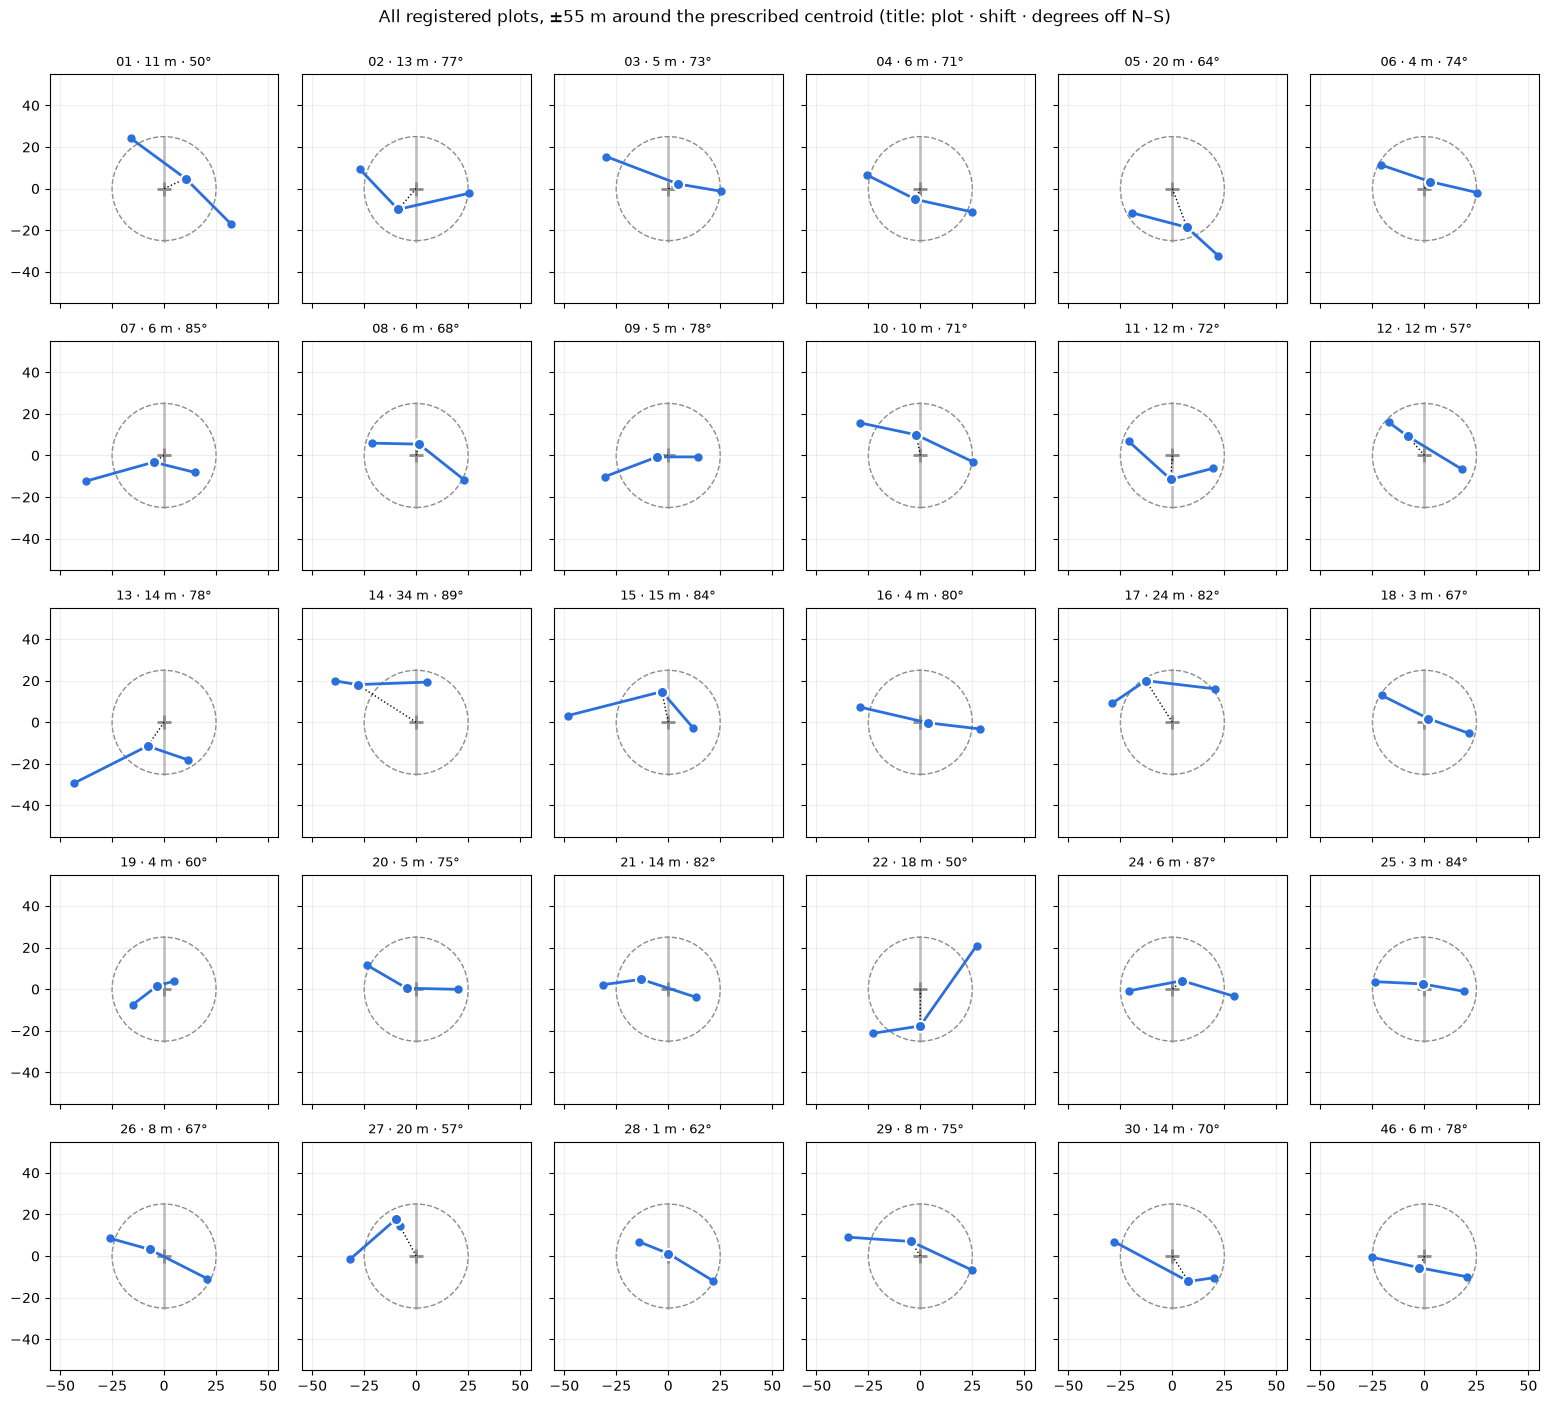

In [15]:
# Each plot in local metres around its prescribed centroid: where the team was sent (grey) and the
# transect they recorded (blue). Same scale in every panel so shifts and rotations are comparable.
TRANSECT_C, PRESCRIBED_C = "#2a6fdb", "#8c8c8c"
MAX_MIDPOINT_SHIFT_M = 25  # SOP: midpoint may move at most 25 m from the prescribed point
HALF_LENGTH_M = 25  # midpoint to endpoint

def xy_m(lat, lon, lat0, lon0):
    """Local equirectangular projection in metres around (lat0, lon0). Accurate to < 0.1 % at plot scale."""
    x = (np.asarray(lon) - lon0) * 111_320 * np.cos(np.radians(lat0))
    y = (np.asarray(lat) - lat0) * 110_574
    return x, y

def draw_plot(ax, r, annotate=False):
    pts = {p: xy_m(r[f"{p}_lat"], r[f"{p}_lon"], r["centroid_lat"], r["centroid_lon"])
           for p in ["endpoint_a", "midpoint", "endpoint_b"]}
    ax.add_patch(plt.Circle((0, 0), MAX_MIDPOINT_SHIFT_M, fill=False, ls="--", lw=1, color=PRESCRIBED_C))
    ax.plot([0, 0], [-HALF_LENGTH_M, HALF_LENGTH_M], color=PRESCRIBED_C, lw=2, alpha=0.5)  # SOP transect
    ax.plot(0, 0, "+", color=PRESCRIBED_C, ms=10, mew=2)
    (ax_, ay), (mx, my), (bx_, by_) = pts["endpoint_a"], pts["midpoint"], pts["endpoint_b"]
    ax.plot([0, mx], [0, my], ":", color="black", lw=1)  # midpoint shift
    ax.plot([ax_, mx, bx_], [ay, my, by_], "-o", color=TRANSECT_C, lw=2, ms=5)
    ax.plot(mx, my, "o", color=TRANSECT_C, ms=8, mec="white", mew=1.5)
    if annotate:
        for (x, y), lab in [(pts["endpoint_a"], "A"), (pts["midpoint"], "midpoint"), (pts["endpoint_b"], "B")]:
            ax.annotate(lab, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=10)
        ax.annotate("prescribed\ncentroid", (0, 0), xytext=(-60, -30), textcoords="offset points",
                    fontsize=9, color="dimgrey")
        ax.annotate(f"{MAX_MIDPOINT_SHIFT_M} m allowed shift", (0, -MAX_MIDPOINT_SHIFT_M), xytext=(0, -14),
                    textcoords="offset points", ha="center", fontsize=9, color="dimgrey")
    ax.set(xlim=(-55, 55), ylim=(-55, 55), aspect="equal")
    ax.grid(alpha=0.2)


geo = plots.dropna(subset=["midpoint_lat", "endpoint_a_lat", "endpoint_b_lat"]).sort_values("plot_name")

# 1. One plot, annotated, to read the small multiples below.
ex = geo.loc[geo["midpoint_shift_m"].idxmax()]
fig, ax = plt.subplots(figsize=(6, 6))
draw_plot(ax, ex, annotate=True)
ax.set(xlabel="east of centroid (m)", ylabel="north of centroid (m)",
       title=f"{ex['plot_name']}\nshift {ex['midpoint_shift_m']:.0f} m · A–mid {ex['a_to_mid_m']:.0f} m · "
             f"B–mid {ex['b_to_mid_m']:.0f} m · {ex['bearing_deviation_deg']:.0f}° off N–S")
ax.legend(handles=[plt.Line2D([], [], color=PRESCRIBED_C, lw=2, alpha=0.5, label="SOP: 50 m N–S at centroid"),
                   plt.Line2D([], [], color=TRANSECT_C, lw=2, marker="o", label="recorded A–midpoint–B"),
                   plt.Line2D([], [], color="black", ls=":", label="midpoint shift")],
          loc="upper right", fontsize=8)
plt.show()

# 2. All plots at the same scale.
ncol = 6
fig, axes = plt.subplots(int(np.ceil(len(geo) / ncol)), ncol, figsize=(2.6 * ncol, 2.8 * np.ceil(len(geo) / ncol)),
                         sharex=True, sharey=True)
for ax, (_, r) in zip(axes.flat, geo.iterrows()):
    draw_plot(ax, r)
    ax.set_title(f"{r['plot_name'].split('_')[-1]} · {r['midpoint_shift_m']:.0f} m · "
                 f"{r['bearing_deviation_deg']:.0f}°", fontsize=9)
for ax in axes.flat[len(geo):]:
    ax.set_visible(False)
fig.suptitle("All registered plots, ±55 m around the prescribed centroid (title: plot · shift · degrees off N–S)",
             y=1.0)
fig.tight_layout()
plt.show()

### 2.2 Surveys and quadrats

This cell builds two clean tables from the raw survey export. It also measures how far the field data sits from the registered plot.

**`surveys`: one row per survey submission.**
- Renames the raw form fields to short column names: plot, replicate, recorder, device, start and end time, review state, and the GPS point taken when the survey was closed.
- `team_size` counts the team member IDs, which the form stores as one space-separated string.
- `duration_min` is the time from survey start to survey end.
- `is_valid` is false only for submissions a reviewer rejected. Rejected surveys stay in the table but are excluded from the metrics.
- `end_to_plot_m` is the distance from the survey's end GPS point to the plot's registered midpoint. A large value suggests the survey was closed away from the plot.

**`quadrats`: one row per quadrat inside a survey.**
- Each quadrat is linked to its survey through `PARENT_KEY`. It inherits the plot name, plot ID and `is_valid` flag from that survey.
- It records the quadrat number, whether herbs or additional species were present, the selected species IDs, and the quadrat's own GPS point.

**Distance checks for each quadrat.** All positions are first converted to metres around the plot midpoint.
- `dist_to_midpoint_m` is the straight-line distance from the quadrat to the registered midpoint.
- `dist_to_line_m` is the distance from the quadrat to the recorded transect between endpoint A and endpoint B. The code finds the closest point on that line segment and measures to it. Here `t` is how far along the segment that closest point lies, from 0 at A to 1 at B. Clipping `t` to that range means quadrats beyond either end are measured to the nearest endpoint.

Quadrats should lie on the transect, so a large `dist_to_line_m` flags a quadrat recorded off the line. The last line prints the number of surveys, valid surveys, quadrats and registered plots.

In [17]:
# clean
surveys = pd.DataFrame({
    "survey_key": survey_raw["KEY"],
    "vegplot_id": survey_raw["plot_selection-selected_plot_uuid"],
    "plot_name": survey_raw["plot_selection-plot_name"],
    "replicate": survey_raw["survey_begin-replicate"],
    "recorder": survey_raw["field_team_specifics-recorder_label"],
    "team_size": survey_raw["field_team_specifics-selected_project_team_uuid_multi"].str.split().str.len(),
    "device": survey_raw["DeviceID"],
    "start": pd.to_datetime(survey_raw["survey_begin-start_time"], utc=True),
    "end": pd.to_datetime(survey_raw["survey_end-end_time"], utc=True),
    "review_state": survey_raw["ReviewState"].fillna("not reviewed"),
    "end_lat": survey_raw["survey_end-background_geopoint-Latitude"],
    "end_lon": survey_raw["survey_end-background_geopoint-Longitude"],
    "end_accuracy_m": survey_raw["survey_end-background_geopoint-Accuracy"],
})
surveys["date"] = surveys["start"].dt.date
surveys["duration_min"] = (surveys["end"] - surveys["start"]).dt.total_seconds() / 60
surveys["is_valid"] = surveys["review_state"] != "rejected"  # rejected submissions are excluded from metrics
surveys = surveys.merge(plots[["vegplot_id", "midpoint_lat", "midpoint_lon"]], on="vegplot_id", how="left")
surveys["end_to_plot_m"] = dist_m(surveys["end_lat"], surveys["end_lon"], surveys["midpoint_lat"], surveys["midpoint_lon"])

H = "herb_species-"
quadrats = pd.DataFrame({
    "quadrat_key": quadrat_raw["KEY"],
    "survey_key": quadrat_raw["PARENT_KEY"],
    "quadrat_number": quadrat_raw["quadrat_number"],
    "herbs_present": quadrat_raw["herbs_present"],
    "additional_species_present": quadrat_raw["additional_species_present"],
    "list_species_uuids": quadrat_raw[f"{H}selected_herb_species_uuids"],
    "lat": quadrat_raw["location_quadrat-Latitude"],
    "lon": quadrat_raw["location_quadrat-Longitude"],
    "accuracy_m": quadrat_raw["location_quadrat-Accuracy"],
}).merge(surveys[["survey_key", "plot_name", "vegplot_id", "is_valid"]], on="survey_key", how="left")

# Distance of each quadrat to the registered midpoint and to the A-B transect line.
q = quadrats.merge(plots[["vegplot_id", "endpoint_a_lat", "endpoint_a_lon", "midpoint_lat", "midpoint_lon",
                          "endpoint_b_lat", "endpoint_b_lon"]], on="vegplot_id", how="left")
ax_, ay_ = xy_m(q["endpoint_a_lat"], q["endpoint_a_lon"], q["midpoint_lat"], q["midpoint_lon"])
bx_, by_ = xy_m(q["endpoint_b_lat"], q["endpoint_b_lon"], q["midpoint_lat"], q["midpoint_lon"])
px_, py_ = xy_m(q["lat"], q["lon"], q["midpoint_lat"], q["midpoint_lon"])
t = (((px_ - ax_) * (bx_ - ax_) + (py_ - ay_) * (by_ - ay_)) / ((bx_ - ax_) ** 2 + (by_ - ay_) ** 2)).clip(0, 1)
quadrats["dist_to_midpoint_m"] = np.hypot(px_, py_)
quadrats["dist_to_line_m"] = np.hypot(px_ - (ax_ + t * (bx_ - ax_)), py_ - (ay_ + t * (by_ - ay_)))

print(f"{len(surveys)} surveys ({surveys['is_valid'].sum()} not rejected), {len(quadrats)} quadrats, "
      f"{len(plots)} registered plots")

32 surveys (30 not rejected), 640 quadrats, 31 registered plots


In [18]:
surveys.head()

,survey_key,vegplot_id,plot_name,replicate,recorder,team_size,device,start,end,review_state,end_lat,end_lon,end_accuracy_m,date,duration_min,is_valid,midpoint_lat,midpoint_lon,end_to_plot_m
0,uuid:599e04cf-832f-4535-8305-967918d12026,b1e1fc7f-afbd-404c-bd6c-55b172d722df,SavMon_LW_Plot_16,lw_baseline,Grace,3,collect:demo-device-01,2026-05-27 07:41:43.843000+00:00,2026-05-27 08:33:03.881000+00:00,not reviewed,0.219603,37.481112,1.50,2026-05-27,51.333967,True,0.219544,37.481276,19.369063
1,uuid:c6cc7231-7af6-4bc5-b281-565c53f21763,8070570d-64ca-405a-802d-4d721fdc2fe9,SavMon_LW_Plot_21,lw_baseline,Sam,3,collect:demo-device-02,2026-05-26 12:48:42.442000+00:00,2026-05-26 13:13:14.012000+00:00,rejected,NaN,NaN,NaN,2026-05-26,24.526167,False,0.225601,37.456848,NaN
2,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513,8070570d-64ca-405a-802d-4d721fdc2fe9,SavMon_LW_Plot_21,lw_baseline,Grace,3,collect:demo-device-01,2026-05-26 07:44:02.068000+00:00,2026-05-26 08:51:37.085000+00:00,not reviewed,0.225574,37.456742,1.90,2026-05-26,67.583617,True,0.225601,37.456848,12.063766
3,uuid:cf362fbc-991a-4db1-8d49-6c1d29fd49c8,a5b642c6-e8ba-4186-a1d3-5ff99852e8b0,SavMon_LW_Plot_18,lw_baseline,Grace,3,collect:demo-device-01,2026-05-26 06:23:51.656000+00:00,2026-05-26 07:17:19.761000+00:00,not reviewed,0.222560,37.438887,3.90,2026-05-26,53.468417,True,0.222530,37.439150,29.529396
4,uuid:9e1251bb-84c1-4b7a-a8bb-bafcf7afc82c,e3135c68-679c-4b44-a083-5dc111683665,SavMon_LW_Plot_11,lw_baseline,Grace,3,collect:demo-device-03,2026-05-26 13:31:46.221000+00:00,2026-05-26 14:25:30.694000+00:00,not reviewed,0.222389,37.466376,2.15,2026-05-26,53.741217,True,0.222224,37.466547,26.366322


### 2.3 Species records (one row per species per quadrat)

Species reach the data in two ways:

* **List species** are picked from the project species list. The quadrat stores space-separated UUIDs that
  join to `species.csv`.
* **Additional species** are either missing from the list (free-text canonical) or unknown (provisional
  `herb_###` code). Each one is an entity in `species_extra.csv`. The later identifications in
  `species_extra_ids.csv` give the name the species was identified as.

The resolved name is the identification if there is one. Otherwise it is the provisional code, so an
unidentified species still counts as one morphospecies.

In [ ]:
# 1. Species ticked from the species list: one row per quadrat and species.
list_records = quadrats[["quadrat_key", "list_species_uuids"]].dropna().copy()
list_records["entity_id"] = list_records["list_species_uuids"].str.split()  # space-separated IDs -> list
list_records = list_records.explode("entity_id")  # one row per ID
list_records = list_records.merge(species[["__id", "label"]], left_on="entity_id", right_on="__id", how="left")
list_records["source"] = "species list"
list_records["recorded_name"] = list_records["label"]
list_records["resolved_name"] = list_records["label"]  # list species are already identified
list_records["provisional_code"] = None
list_records["id_note"] = None

# 2. Extra species created in the field, with their later identification (if any).
extra = species_extra.copy()
extra["provisional_code"] = "herb_" + extra["unknown_index"].astype(str).str.zfill(3)  # e.g. herb_007
extra = extra.merge(species_ids[["species_number", "species_name", "notes"]], left_on="provisional_code",
                    right_on="species_number", how="left")

# 3. Additional species recorded in a quadrat. New entries point to the entity they create,
#    reused entries to the entity they pick, so take whichever of the three fields is filled.
entity_id = addsp_raw["target_extra_name"]
entity_id = entity_id.fillna(addsp_raw["select_reuse_unknown"])
entity_id = entity_id.fillna(addsp_raw["select_reuse_missing"])
add_records = pd.DataFrame({
    "quadrat_key": addsp_raw["PARENT_KEY"],
    "record_key": addsp_raw["KEY"],
    "entity_id": entity_id,
})
extra_cols = ["__id", "label", "provisional_code", "species_name", "notes", "new_record_reason"]
add_records = add_records.merge(extra[extra_cols], left_on="entity_id", right_on="__id", how="left")

SOURCE_LABELS = {"missing_species": "additional (missing from list)", "unknown_species": "additional (unknown)"}
add_records["source"] = add_records["new_record_reason"].map(SOURCE_LABELS)
add_records["recorded_name"] = add_records["label"]
# Use the identified name. Fall back to the provisional code while the species is still unknown.
still_unknown = add_records["species_name"].isna() | (add_records["species_name"] == "Unknown")
add_records["resolved_name"] = np.where(still_unknown, add_records["provisional_code"], add_records["species_name"])
add_records["id_note"] = add_records["notes"]

# 4. Combine both sources into one table of species records.
cols = ["quadrat_key", "source", "entity_id", "provisional_code", "recorded_name", "resolved_name", "id_note"]
records = pd.concat([list_records[cols], add_records[cols + ["record_key"]]], ignore_index=True)
records["resolved_name"] = records["resolved_name"].str.strip()  # the only normalisation (see top)
records["is_unidentified"] = records["resolved_name"].str.match(r"^herb_\d{3}$", na=False)
records = records.merge(quadrats[["quadrat_key", "survey_key", "plot_name", "is_valid"]], on="quadrat_key")

,records,names
source,,
additional (missing from list),622,42
additional (unknown),673,56
species list,947,28


In [21]:
records.head()

,quadrat_key,source,entity_id,provisional_code,recorded_name,resolved_name,id_note,record_key,is_unidentified,survey_key,plot_name,is_valid
0,uuid:599e04cf-832f-4535-8305-967918d12026/obse...,species list,3c3ff64b-92fd-4d60-9022-63a7c599e108,None,Ocimum americanum,Ocimum americanum,None,NaN,False,uuid:599e04cf-832f-4535-8305-967918d12026,SavMon_LW_Plot_16,True
1,uuid:599e04cf-832f-4535-8305-967918d12026/obse...,species list,e3454aa0-e2f6-495b-9aea-90847fdd1858,None,Indigofera schimperi,Indigofera schimperi,None,NaN,False,uuid:599e04cf-832f-4535-8305-967918d12026,SavMon_LW_Plot_16,True
2,uuid:599e04cf-832f-4535-8305-967918d12026/obse...,species list,f407986d-94a5-4fa9-a058-b9f183687960,None,Sida cordifolia,Sida cordifolia,None,NaN,False,uuid:599e04cf-832f-4535-8305-967918d12026,SavMon_LW_Plot_16,True
3,uuid:599e04cf-832f-4535-8305-967918d12026/obse...,species list,3c3ff64b-92fd-4d60-9022-63a7c599e108,None,Ocimum americanum,Ocimum americanum,None,NaN,False,uuid:599e04cf-832f-4535-8305-967918d12026,SavMon_LW_Plot_16,True
4,uuid:599e04cf-832f-4535-8305-967918d12026/obse...,species list,e3454aa0-e2f6-495b-9aea-90847fdd1858,None,Indigofera schimperi,Indigofera schimperi,None,NaN,False,uuid:599e04cf-832f-4535-8305-967918d12026,SavMon_LW_Plot_16,True


In [22]:

records.groupby("source").agg(records=("quadrat_key", "size"), names=("resolved_name", "nunique"))

,records,names
source,,
additional (missing from list),622,42
additional (unknown),673,56
species list,947,28


### 2.4 Taxonomic check of free-text names against GBIF

Names typed in the field, or added during identification, are not checked against any taxonomy. The
project species list carries GBIF taxon keys, so the GBIF backbone is the natural reference. I match each
free-text name with the GBIF species-match API. This cell needs an internet connection.

In [26]:
# Names typed in the field that are not provisional codes like herb_007.
is_free_text = (records["source"] != "species list") & ~records["is_unidentified"]
free_text = sorted(records.loc[is_free_text, "resolved_name"].dropna().unique())
free_text[:10]

['Abutilon ramosum',
 'Alectra orobanchoides',
 'Aristida scabrivalvis',
 'Asparagus africanus',
 'Blepharis maderaspatensis',
 'Boerhavia coccinea',
 'Brachiara dura',
 'Canavalia rosea',
 'Cenchrus bifloris',
 'Cenchrus ciliaris']

In [27]:
def match_gbif(name):
    """Look up one plant name in the GBIF backbone taxonomy."""
    query = urllib.parse.urlencode({"name": name, "kingdom": "Plantae"})
    url = "https://api.gbif.org/v1/species/match?" + query
    with urllib.request.urlopen(url, timeout=20) as response:
        match = json.load(response)
    return {
        "name": name,
        "match_type": match.get("matchType"),
        "rank": match.get("rank"),
        "status": match.get("status"),
        "gbif_canonical": match.get("canonicalName"),
        "gbif_accepted": match.get("species"),
        "confidence": match.get("confidence"),
    }


gbif = pd.DataFrame([match_gbif(name) for name in free_text])
gbif.head()

,name,match_type,rank,status,gbif_canonical,gbif_accepted,confidence
0,Abutilon ramosum,EXACT,SPECIES,ACCEPTED,Abutilon ramosum,Abutilon ramosum,99
1,Alectra orobanchoides,EXACT,SPECIES,ACCEPTED,Alectra orobanchoides,Alectra orobanchoides,100
2,Aristida scabrivalvis,EXACT,SPECIES,ACCEPTED,Aristida scabrivalvis,Aristida scabrivalvis,100
3,Asparagus africanus,EXACT,SPECIES,ACCEPTED,Asparagus africanus,Asparagus africanus,100
4,Blepharis maderaspatensis,EXACT,SPECIES,ACCEPTED,Blepharis maderaspatensis,Blepharis maderaspatensis,99


In [ ]:
gbif["match_type"].value_counts()

match_type
EXACT         48
FUZZY         17
HIGHERRANK     2
Name: count, dtype: int64

## 3. QA/QC checks

Every check adds rows to one `flags` table: `check_id`, `severity`, `check`, `record_key` (the flagged record),
`plot_name` and `detail` (the observed value). I kept the checks that change how the data can be used:

| ID | Check | Severity | Why it matters |
|---|---|---|---|
| S01 | Submission rejected in ODK review | info | excluded from all metrics |
| S02 | Plot surveyed twice in the same replicate | warning | would double count the plot |
| S05 | Survey duration outside 30–180 min | warning | rushed or interrupted survey |
| P01 | Plot registered as not viable | info | explains a missing plot |
| P02 | Midpoint more than 25 m from the prescribed point | error | plot is not where the design put it |
| P03 | Endpoint not 25 ± 10 m from the midpoint | warning | transect has the wrong length |
| P04 | Transect more than 45° off north–south | warning | SOP orientation not followed |
| Q01 | Quadrat more than 32.5 m from the midpoint | warning | quadrat outside the belt transect |
| Q04 | "Additional species present" but none recorded | error | species records are missing |
| T01 | Additional-species record without a species | error | species record is missing |
| T02 | Provisional species not yet identified | warning | richness counts a morphospecies |
| T03 | Free-text name has no exact species match in GBIF | warning | typos inflate richness |
| T06 | Woody species recorded in the herbaceous survey | warning | out of scope for this survey |

Species checks (T02, T03, T06) give one flag per taxon per plot, so they can be filtered by plot.

In [29]:
# constants
ENDPOINT_TOLERANCE_M = 10  # endpoint-midpoint distance accepted as 25 +/- 10 m (two GPS errors)
SURVEY_MINUTES = (30, 180)  # plausible survey duration
HALF_WIDTH_M = 2.5  # belt half-width
GPS_ACCURACY_M = 5  # SOP: geopoints must be 5 m or better
QUADRAT_MAX_DIST_M = HALF_LENGTH_M + HALF_WIDTH_M + GPS_ACCURACY_M  # 32.5 m from the midpoint
MAX_BEARING_DEVIATION_DEG = 45  # SOP: transects laid out north-south; rotation allowed around obstacles


flags = []


def flag(check_id, severity, check, rows, key, detail_columns=()):
    """Add one flag per row of `rows`. `detail_columns` are shown in the detail text with their values."""
    for _, r in rows.iterrows():
        values = [round(r[c], 1) if isinstance(r[c], float) else r[c] for c in detail_columns]
        flags.append({"check_id": check_id, "severity": severity, "check": check, "record_key": r[key],
                      "plot_name": r["plot_name"],
                      "detail": ", ".join(f"{c} = {v}" for c, v in zip(detail_columns, values))})


# Surveys
s = surveys
flag("S01", "info", "Submission rejected in ODK review", s[~s["is_valid"]], "survey_key", ["review_state"])
flag("S02", "warning", "Plot surveyed more than once in the same replicate",
     s[s.duplicated(["vegplot_id", "replicate"], keep=False)], "survey_key", ["date", "recorder"])
flag("S05", "warning", f"Survey duration outside {SURVEY_MINUTES[0]}–{SURVEY_MINUTES[1]} min",
     s[~s["duration_min"].between(*SURVEY_MINUTES)], "survey_key", ["duration_min"])

# Plots
p = plots
flag("P01", "info", "Plot registered as not viable", p[p["is_viable"] != "yes"], "plot_uuid", ["not_viable_reason"])
p = p[p["is_viable"] == "yes"]
flag("P02", "error", f"Midpoint more than {MAX_MIDPOINT_SHIFT_M} m from the prescribed point",
     p[p["midpoint_shift_m"] > MAX_MIDPOINT_SHIFT_M], "plot_uuid", ["midpoint_shift_m"])
a_off = (p["a_to_mid_m"] - HALF_LENGTH_M).abs() > ENDPOINT_TOLERANCE_M
b_off = (p["b_to_mid_m"] - HALF_LENGTH_M).abs() > ENDPOINT_TOLERANCE_M
flag("P03", "warning", f"Endpoint not {HALF_LENGTH_M} ± {ENDPOINT_TOLERANCE_M} m from the midpoint",
     p[a_off | b_off], "plot_uuid", ["a_to_mid_m", "b_to_mid_m"])
flag("P04", "warning", f"Transect more than {MAX_BEARING_DEVIATION_DEG}° off north–south",
     p[p["bearing_deviation_deg"] > MAX_BEARING_DEVIATION_DEG], "plot_uuid", ["bearing_deg"])

# Quadrats
q = quadrats
flag("Q01", "warning", f"Quadrat more than {QUADRAT_MAX_DIST_M} m from the plot midpoint",
     q[q["dist_to_midpoint_m"] > QUADRAT_MAX_DIST_M], "quadrat_key", ["quadrat_number", "dist_to_midpoint_m"])
has_additional = q["quadrat_key"].isin(addsp_raw["PARENT_KEY"])
flag("Q04", "error", "Additional species indicated but none recorded",
     q[(q["additional_species_present"] == "yes") & ~has_additional], "quadrat_key", ["quadrat_number"])

# Species
r = records
flag("T01", "error", "Additional-species record without a species",
     r[(r["source"] != "species list") & r["entity_id"].isna()], "record_key", ["source"])
taxa = records.dropna(subset=["resolved_name"]).drop_duplicates(["plot_name", "resolved_name"])  # taxon per plot
flag("T02", "warning", "Provisional species not yet identified", taxa[taxa["is_unidentified"]], "resolved_name")
not_exact = gbif[(gbif["match_type"] != "EXACT") | (gbif["rank"] != "SPECIES")]
flag("T03", "warning", "Free-text name has no exact species match in GBIF",
     taxa.merge(not_exact, left_on="resolved_name", right_on="name"), "resolved_name",
     ["match_type", "gbif_canonical"])
woody_names = species.loc[species["groups"] == "woody", "label"]
is_woody = taxa["resolved_name"].isin(woody_names) | taxa["id_note"].str.contains("woody", case=False, na=False)
flag("T06", "warning", "Woody species recorded in the herbaceous survey", taxa[is_woody], "resolved_name", ["id_note"])

flags = pd.DataFrame(flags)
flag_overview = flags.groupby(["check_id", "severity", "check"]).size().rename("n_flags").reset_index()
flag_overview

,check_id,severity,check,n_flags
0,P01,info,Plot registered as not viable,1
1,P02,error,Midpoint more than 25 m from the prescribed point,1
2,P03,warning,Endpoint not 25 ± 10 m from the midpoint,9
3,P04,warning,Transect more than 45° off north–south,30
4,Q01,warning,Quadrat more than 32.5 m from the plot midpoint,33
5,Q04,error,Additional species indicated but none recorded,10
6,S01,info,Submission rejected in ODK review,2
7,S02,warning,Plot surveyed more than once in the same repli...,4
8,S05,warning,Survey duration outside 30–180 min,3
9,T01,error,Additional-species record without a species,1


## 4. Survey-level summary

One row per submission, with the survey and quadrat flags it received.

In [31]:
quadrat_counts = quadrats.groupby("survey_key").agg(
    quadrats=("quadrat_key", "size"),
    quadrats_with_herbs=("herbs_present", lambda x: (x == "yes").sum()),
)
species_counts = records.groupby("survey_key").agg(
    species_records=("resolved_name", "size"),
    taxa=("resolved_name", "nunique"),
)
# Quadrat flags belong to the survey the quadrat is part of.
flag_survey_key = flags["record_key"].map(quadrats.set_index("quadrat_key")["survey_key"]).fillna(flags["record_key"])
survey_flags = flags.groupby(flag_survey_key)["check_id"].agg(lambda x: ", ".join(sorted(set(x))))

survey_summary = (
    surveys[["survey_key", "plot_name", "date", "recorder", "duration_min", "review_state"]]
    .join(quadrat_counts, on="survey_key")
    .join(species_counts, on="survey_key")
    .assign(flags=lambda d: d["survey_key"].map(survey_flags).fillna(""))
    .sort_values(["plot_name", "date"])
    .reset_index(drop=True)
)
survey_summary["duration_min"] = survey_summary["duration_min"].round()
survey_summary.drop(columns="survey_key").head()

,plot_name,date,recorder,duration_min,review_state,quadrats,quadrats_with_herbs,species_records,taxa,flags
0,SavMon_LW_Plot_01,2026-05-23,Grace,70.0,not reviewed,20,20,89,31,Q01
1,SavMon_LW_Plot_02,2026-05-24,Grace,100.0,not reviewed,20,19,50,18,Q01
2,SavMon_LW_Plot_03,2026-05-20,Sam,59.0,not reviewed,20,18,43,15,Q01
3,SavMon_LW_Plot_04,2026-05-25,Grace,56.0,not reviewed,20,19,52,20,Q01
4,SavMon_LW_Plot_05,2026-05-22,Grace,102.0,not reviewed,20,19,43,16,Q01


## 5. Plot-level summary

Richness uses only non-rejected surveys. With presence/absence in 20 quadrats per plot, I report

* **observed richness**: number of distinct taxa in the plot,
* **mean richness per quadrat**: average number of taxa in one quadrat, and

In [33]:
valid_records = records[records["is_valid"]].dropna(subset=["resolved_name"])
valid_quadrats = quadrats[quadrats["is_valid"]]

taxon_in_quadrat = valid_records.drop_duplicates(["quadrat_key", "resolved_name"])
richness = pd.DataFrame({
    "observed_richness": valid_records.groupby("plot_name")["resolved_name"].nunique(),
    # empty quadrats count as 0, so divide by all quadrats of the plot
    "mean_richness_per_quadrat": taxon_in_quadrat.groupby("plot_name").size() / valid_quadrats.groupby("plot_name").size(),
})

plot_flags = flags[flags["check_id"].str.startswith("P")].groupby("plot_name")["check_id"].agg(lambda x: ", ".join(sorted(x)))
survey_counts = surveys.groupby("plot_name").agg(surveys=("survey_key", "size"), valid_surveys=("is_valid", "sum"))

plot_summary = (
    plots[["plot_name", "plot_status", "is_viable", "midpoint_shift_m", "a_to_mid_m", "b_to_mid_m", "bearing_deg"]]
    .join(survey_counts, on="plot_name")
    .join(richness, on="plot_name")
    .assign(flags=lambda d: d["plot_name"].map(plot_flags).fillna(""))
    .sort_values("plot_name")
    .reset_index(drop=True)
)
plot_summary.round(2).head()


,plot_name,plot_status,is_viable,midpoint_shift_m,a_to_mid_m,b_to_mid_m,bearing_deg,surveys,valid_surveys,observed_richness,mean_richness_per_quadrat,flags
0,SavMon_LW_Plot_01,primary,yes,11.41,32.75,30.57,130.50,1.0,1.0,31.0,4.45,P04
1,SavMon_LW_Plot_02,primary,yes,13.26,26.88,34.94,102.59,1.0,1.0,18.0,2.50,P04
2,SavMon_LW_Plot_03,primary,yes,5.31,36.99,20.77,106.81,1.0,1.0,15.0,2.15,"P03, P04"
3,SavMon_LW_Plot_04,primary,yes,5.68,26.16,27.72,109.42,1.0,1.0,20.0,2.60,P04
4,SavMon_LW_Plot_05,primary,yes,19.89,27.13,20.16,116.47,1.0,1.0,16.0,2.15,P04


## 6. Sampling effort

1. **Was the design completed?** Planned, registered, not viable and surveyed plots per stratum.
2. **Are 20 quadrats enough per plot?** Species accumulation over quadrats.
3. **Are the plots enough for the project area?** Species accumulation over plots.

An accumulation curve shows how many taxa have been seen after 1, 2, 3, … quadrats (or plots), averaged over
200 random orderings. If the curve flattens, more sampling would add few new taxa.

In [34]:
surveyed_plots = surveys.loc[surveys["is_valid"], "plot_name"]
design = (
    centroids.assign(
        registered=centroids["choice_name"].isin(plots["plot_name"]),
        not_viable=centroids["choice_name"].isin(plots.loc[plots["is_viable"] != "yes", "plot_name"]),
        surveyed=centroids["choice_name"].isin(surveyed_plots),
    )
    .groupby(["stratum_label", "sample_status"])
    .agg(planned=("choice_name", "size"), registered=("registered", "sum"), not_viable=("not_viable", "sum"),
         surveyed=("surveyed", "sum"))
)
design

planned  registered  not_viable  surveyed
stratum_label sample_status                                           
savanna       backup              10           1           0         1
              primary             30          30           1        29
shrubland     backup               5           0           0         0
              primary              6           0           0         0

new taxa added by the 20th quadrat (mean of plots): 0.44
project: 121 taxa in 30 plots, last plot adds 1.2 taxa


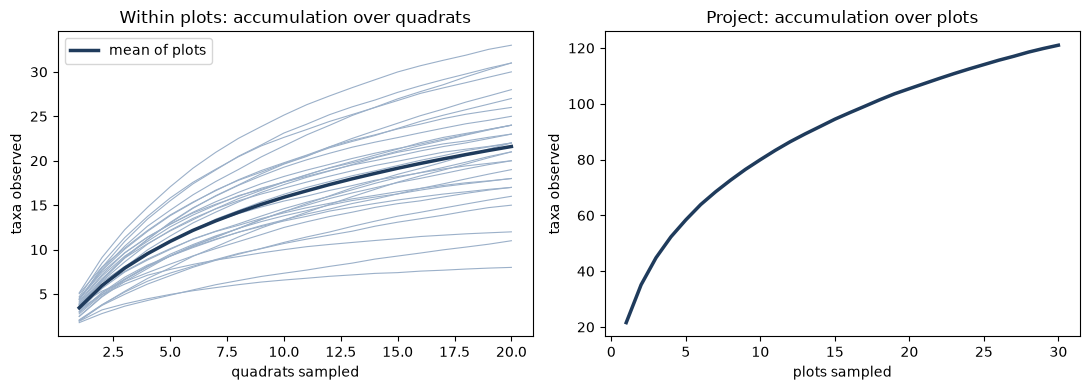

In [36]:
QUADRATS_PER_PLOT = 20

rng = np.random.default_rng(42)

def accumulation(incidence, n_orderings=200):
    """Mean number of taxa seen after 1, 2, ... rows of a presence/absence table, over random row orderings."""
    present = incidence.to_numpy() > 0
    curves = []
    for _ in range(n_orderings):
        shuffled = present[rng.permutation(len(present))]
        seen_so_far = np.logical_or.accumulate(shuffled, axis=0)
        curves.append(seen_so_far.sum(axis=1))
    return np.mean(curves, axis=0)


# Within plots: quadrat x taxon table per plot, keeping quadrats without any herbs.
plot_curves = []
for plot, qq in valid_quadrats.groupby("plot_name"):
    recs = valid_records[valid_records["plot_name"] == plot]
    incidence = pd.crosstab(recs["quadrat_key"], recs["resolved_name"]).reindex(qq["quadrat_key"], fill_value=0)
    plot_curves.append(accumulation(incidence))

# Project: plot x taxon table.
plot_by_taxon = pd.crosstab(valid_records["plot_name"], valid_records["resolved_name"])
project_curve = accumulation(plot_by_taxon)

# How many new taxa the last quadrat / last plot adds: close to 0 means the curve has flattened.
print(f"new taxa added by the 20th quadrat (mean of plots): {np.mean([c[-1] - c[-2] for c in plot_curves]):.2f}")
print(f"project: {plot_by_taxon.shape[1]} taxa in {len(plot_by_taxon)} plots, "
      f"last plot adds {project_curve[-1] - project_curve[-2]:.1f} taxa")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for curve in plot_curves:
    axes[0].plot(range(1, len(curve) + 1), curve, color="#9bb0c9", lw=0.8)
axes[0].plot(range(1, QUADRATS_PER_PLOT + 1), np.mean(plot_curves, axis=0), color="#1f3b5c", lw=2.5,
             label="mean of plots")
axes[0].set(xlabel="quadrats sampled", ylabel="taxa observed", title="Within plots: accumulation over quadrats")
axes[0].legend()
axes[1].plot(range(1, len(project_curve) + 1), project_curve, color="#1f3b5c", lw=2.5)
axes[1].set(xlabel="plots sampled", ylabel="taxa observed", title="Project: accumulation over plots")
fig.tight_layout()
fig.savefig(FIGURES / "veg_species_accumulation.png", dpi=150)

## 7. Map of transect locations

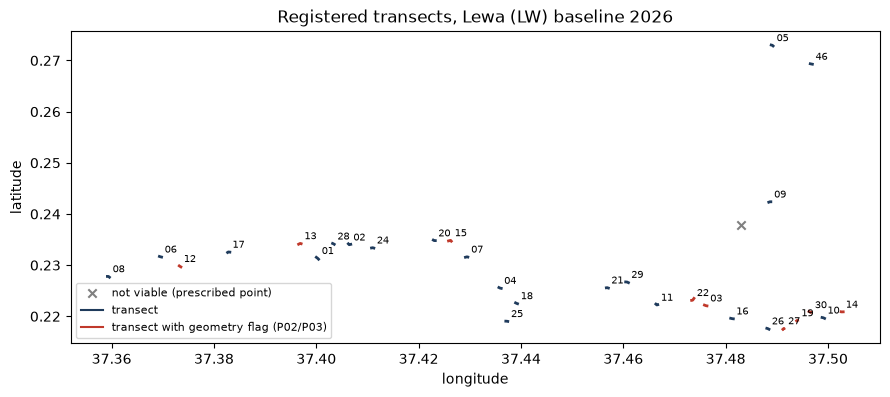

In [37]:
flagged_plots = set(flags.loc[flags["check_id"].isin(["P02", "P03"]), "plot_name"])
outside_belt = set(flags.loc[flags["check_id"] == "Q01", "record_key"])
viable = plots[plots["is_viable"] == "yes"]
not_viable = plots[plots["is_viable"] != "yes"]

fig, ax = plt.subplots(figsize=(9, 6))
for _, r in viable.iterrows():
    color = "#c0392b" if r["plot_name"] in flagged_plots else "#1f3b5c"
    ax.plot([r["endpoint_a_lon"], r["midpoint_lon"], r["endpoint_b_lon"]],
            [r["endpoint_a_lat"], r["midpoint_lat"], r["endpoint_b_lat"]], color=color, lw=2)
    ax.annotate(r["plot_name"].split("_")[-1], (r["midpoint_lon"], r["midpoint_lat"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.scatter(not_viable["centroid_lon"], not_viable["centroid_lat"], marker="x", color="grey",
           label="not viable (prescribed point)")
ax.plot([], [], color="#1f3b5c", label="transect")
ax.plot([], [], color="#c0392b", label="transect with geometry flag (P02/P03)")
ax.set(xlabel="longitude", ylabel="latitude", title="Registered transects, Lewa (LW) baseline 2026")
ax.set_aspect(1 / np.cos(np.radians(viable["midpoint_lat"].mean())))
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES / "veg_transect_map.png", dpi=150)

## 8. Write outputs

In [41]:
flags.to_csv(OUT / "flags.csv", index=False)
flag_overview.to_csv(OUT / "flag_overview.csv", index=False)
survey_summary.to_csv(OUT / "survey_summary.csv", index=False)
plot_summary.round(3).to_csv(OUT / "plot_summary.csv", index=False)
records.to_csv(OUT / "species_records.csv", index=False)
design.to_csv(OUT / "sampling_design.csv")
print("written to", OUT.relative_to(ROOT))

written to data/output/vegetation
